# E2 — Semi-supervisão com consistência temporal

Arquitetura vencedora do E1 (DeepLabV3+, trocável em `ARCHS`) em seis cenários, **com os mesmos lotes**
(8 frames rotulados + 8 centrais não rotulados por passo):

| método | perda |
|---|---|
| `supervised` | $\mathcal L_{sup}$ |
| `fixmatch` | $\mathcal L_{sup} + \lambda(s)\,\mathcal L_{FM}$ |
| `meanteacher` | $\mathcal L_{sup} + \lambda_{MT}(s)\,\mathcal L_{MT}$ |
| `mt-temporal-prev` | $+\ \lambda_{temp}(s)\,\mathcal L_{temp}$, vizinho $t-1$ transportado para $t$ |
| `mt-temporal-bi` | $+\ \lambda_{temp}(s)\,\mathcal L_{temp}$, vizinhos $t-1$ e $t+1$ transportados para $t$ |
| `mt-temporal-prev3` | $+\ \lambda_{temp}(s)\,\mathcal L_{temp}$, vizinho $t-3$ transportado para $t$ (T=3; compara a distância do vizinho com o `prev`) |

O alvo de $\mathcal L_{MT}$ e $\mathcal L_{temp}$ é o teacher EMA; o student é a única rede otimizada. O
transporte usa fluxo óptico Farneback (convenção DTC-TRUS) e é ponderado por
$M_{noc}=\exp(-\alpha|I_t-W(I_n)|)$. $\lambda_{temp}$ fica em zero no warm-up e só então começa a sua rampa.

**Regime:** treino final nos 80 pacientes de desenvolvimento (todos os rótulos + todo frame nunca anotado
desses vídeos), checkpoint pela validação fixa (`val/dice_patient`), avaliação única no **teste INCA**
(23 pacientes) e no **UNM** inteiro. Agregação: frames → paciente → média dos pacientes.

Config: `configs/sweep/e2.yaml`; lógica: `src/sweeps/e2.py`.

In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
import sys
sys.path.append("../../../")

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from src.evaluation import comparison_table, table_to_markdown
from src.sweep import Sweep, submit_sweep, sweep_status, watch_sweep

SWEEP_CONFIG = "configs/sweep/e2.yaml"

# Grade. Trocar a arquitetura aqui NAO edita o YAML: vira `--set axes.arch=[...]` no processo do tmux.
ARCHS = ["deeplabv3plus"]            # qualquer chave de `arch_configs` (unet, fpn, ...)
POLICIES = ["global"]                # ["global", "same_video"] para comparar a origem dos nao rotulados
SEEDS = [42]
REFERENCE_METHOD = "supervised"

OVERRIDES = {"axes.arch": ARCHS, "axes.unlabeled_policy": POLICIES, "axes.seed": SEEDS}
sweep = Sweep(SWEEP_CONFIG, overrides=OVERRIDES)
sweep.plan_summary()

/home/caioseda/miniconda3/envs/vfss/lib/python3.12/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


,run_id,seed,arch,unlabeled_policy,method,status
0,deeplabv3plus-supervised-global-s42,42,deeplabv3plus,global,supervised,done (na CSV)
1,deeplabv3plus-fixmatch-global-s42,42,deeplabv3plus,global,fixmatch,done (na CSV)
2,deeplabv3plus-meanteacher-global-s42,42,deeplabv3plus,global,meanteacher,done (na CSV)
3,deeplabv3plus-mt-temporal-prev-global-s42,42,deeplabv3plus,global,mt-temporal-prev,done (na CSV)
4,deeplabv3plus-mt-temporal-bi-global-s42,42,deeplabv3plus,global,mt-temporal-bi,done (na CSV)
5,deeplabv3plus-mt-temporal-prev3-global-s42,42,deeplabv3plus,global,mt-temporal-prev3,done (na CSV)


## Execução

O treino roda numa sessão tmux (`e2`); fechar o notebook não o interrompe.

In [5]:
sweep_status(SWEEP_CONFIG, overrides=OVERRIDES)

,run_id,seed,arch,unlabeled_policy,method,status
0,deeplabv3plus-supervised-global-s42,42,deeplabv3plus,global,supervised,done (na CSV)
1,deeplabv3plus-fixmatch-global-s42,42,deeplabv3plus,global,fixmatch,done (na CSV)
2,deeplabv3plus-meanteacher-global-s42,42,deeplabv3plus,global,meanteacher,done (na CSV)
3,deeplabv3plus-mt-temporal-prev-global-s42,42,deeplabv3plus,global,mt-temporal-prev,done (na CSV)
4,deeplabv3plus-mt-temporal-bi-global-s42,42,deeplabv3plus,global,mt-temporal-bi,done (na CSV)
5,deeplabv3plus-mt-temporal-prev3-global-s42,42,deeplabv3plus,global,mt-temporal-prev3,done (na CSV)


In [6]:
# submit_sweep(SWEEP_CONFIG, overrides=OVERRIDES)
watch_sweep(SWEEP_CONFIG, overrides=OVERRIDES)

e2: 6/6 celulas concluidas (11:32:02)
                                    run_id  seed          arch unlabeled_policy            method        status
       deeplabv3plus-supervised-global-s42    42 deeplabv3plus           global        supervised done (na CSV)
         deeplabv3plus-fixmatch-global-s42    42 deeplabv3plus           global          fixmatch done (na CSV)
      deeplabv3plus-meanteacher-global-s42    42 deeplabv3plus           global       meanteacher done (na CSV)
 deeplabv3plus-mt-temporal-prev-global-s42    42 deeplabv3plus           global  mt-temporal-prev done (na CSV)
   deeplabv3plus-mt-temporal-bi-global-s42    42 deeplabv3plus           global    mt-temporal-bi done (na CSV)
deeplabv3plus-mt-temporal-prev3-global-s42    42 deeplabv3plus           global mt-temporal-prev3 done (na CSV)

--- console ---
grade e2: 100%|##########| 6/6 [2:13:19<00:00, 1333.33s/cell]

Concluido. 6 celulas treinadas nesta sessao.

Grade completa.


## Resultados por frame e custo por run

In [7]:
results = sweep.load_results()
resources = sweep.plan.load_resources()
results = results[results.arch.isin(ARCHS) & results.unlabeled_policy.isin(POLICIES) & results.seed.isin(SEEDS)]
resources = resources[resources.arch.isin(ARCHS) & resources.unlabeled_policy.isin(POLICIES) & resources.seed.isin(SEEDS)]
assert set(results.eval_set) <= {"inca_test", "unm"}
results.groupby(["arch", "unlabeled_policy", "method", "eval_set"]).size().unstack()

eval_set                                          inca_test  unm
arch          unlabeled_policy method                           
deeplabv3plus global           fixmatch                 239  325
                               meanteacher              239  325
                               mt-temporal-bi           239  325
                               mt-temporal-prev         239  325
                               mt-temporal-prev3        239  325
                               supervised               239  325

## Tabela comparativa

Acurácia no teste INCA e no UNM (média por paciente; `±` = desvio entre pacientes com uma seed, entre seeds
com várias), diferença **pareada por paciente** contra o supervisionado, e custo: tempo total de parede,
s/passo, fração do treino esperando o DataLoader (fluxo óptico nos workers), pico de VRAM (alocado) no
treino e na inferência, parâmetros do student e do teacher, GFLOPs por frame a 256×256, latência de
inferência, imagens por passo em cada rede, tamanho do checkpoint e passo do melhor checkpoint.

In [8]:
BY = ["arch", "unlabeled_policy", "method"]
table = comparison_table(results, resources, by=BY, reference=REFERENCE_METHOD)
METHOD_ORDER = ["supervised", "fixmatch", "meanteacher", "mt-temporal-prev", "mt-temporal-prev3", "mt-temporal-bi"]
table["method"] = pd.Categorical(table["method"], METHOD_ORDER, ordered=True)
table = table.sort_values(BY).reset_index(drop=True)

out_dir = Path(sweep.family_dir)
table.to_csv(out_dir / "comparison_table.csv", index=False)
(out_dir / "comparison_table.md").write_text(table_to_markdown(table))
pd.set_option("display.max_columns", None)
table.round(4)

,arch,unlabeled_policy,method,inca_test dice,inca_test ± dice,inca_test iou,inca_test ± iou,inca_test assd,inca_test ± assd,inca_test hd95,inca_test ± hd95,unm dice,unm ± dice,unm iou,unm ± iou,unm assd,unm ± assd,unm hd95,unm ± hd95,± entre,tempo total (h),s/passo,espera por dados (%),VRAM treino (GB),VRAM inferência (GB),params student (M),params teacher (M),params treináveis (M),GFLOPs/frame,latência bs1 (ms/frame),latência bs8 (ms/frame),imagens/passo student,imagens/passo teacher,checkpoint (MB),passo do melhor ckpt
0,deeplabv3plus,global,supervised,0.8670,0.0494,0.7696,0.0715,1.3651,0.6357,5.8906,4.1983,0.7925,0.0589,0.6640,0.0763,6.7600,6.9100,33.8031,32.0145,pacientes,0.2323,0.1144,42.5488,1.5969,1.2789,22.4377,0.0000,22.4377,15.7701,4.7035,0.6006,16.0000,NaN,257.1506,6500.0
1,deeplabv3plus,global,fixmatch,0.8705,0.0383,0.7739,0.0574,1.3023,0.4534,5.4877,3.2490,0.8109,0.0506,0.6891,0.0661,1.7178,0.7624,6.2984,4.4165,pacientes,0.1994,0.1438,16.2755,2.2288,1.2520,22.4377,0.0000,22.4377,15.7701,4.7611,0.6031,23.5253,NaN,257.1335,4500.0
2,deeplabv3plus,global,meanteacher,0.8759,0.0402,0.7827,0.0606,1.2075,0.4731,5.0818,2.9972,0.8089,0.0646,0.6876,0.0853,3.8437,5.9282,16.2851,26.6811,pacientes,0.0948,0.1164,32.2356,1.8751,1.3376,22.4377,22.4377,22.4377,15.7701,4.8138,0.6049,16.0000,7.1456,342.8880,2500.0
3,deeplabv3plus,global,mt-temporal-prev,0.8723,0.0465,0.7777,0.0697,1.2086,0.5274,4.8122,3.7305,0.8225,0.0487,0.7045,0.0653,1.5663,0.8026,5.8308,4.4504,pacientes,0.0961,0.1533,40.3886,2.1972,1.3376,22.4377,22.4377,22.4377,15.7701,4.7169,0.5903,16.0000,13.8345,342.8840,2000.0
4,deeplabv3plus,global,mt-temporal-prev3,0.8763,0.0397,0.7835,0.0603,1.1745,0.4183,4.6701,2.7678,0.8091,0.0510,0.6866,0.0676,3.2623,3.4104,16.1762,20.0779,pacientes,0.1481,0.1572,42.7684,2.0252,1.3376,22.4377,22.4377,22.4377,15.7701,4.7524,0.5942,16.0000,14.4727,342.8925,3000.0
5,deeplabv3plus,global,mt-temporal-bi,0.8767,0.0425,0.7842,0.0636,1.1906,0.4869,4.7538,2.7672,0.8189,0.0459,0.6985,0.0629,2.1686,1.9876,10.4620,14.4827,pacientes,0.1198,0.1959,53.1713,2.4272,1.3376,22.4377,22.4377,22.4377,15.7701,8.0842,1.0096,16.0000,20.7275,342.8839,2000.0


### Só acurácia (para o texto)

In [9]:
accuracy_cols = BY + [c for c in table.columns if c.startswith(("inca_test", "unm")) and ("dice" in c or "hd95" in c)]
table[accuracy_cols].round(4)

,arch,unlabeled_policy,method,inca_test dice,inca_test ± dice,inca_test hd95,inca_test ± hd95,unm dice,unm ± dice,unm hd95,unm ± hd95
0,deeplabv3plus,global,supervised,0.8670,0.0494,5.8906,4.1983,0.7925,0.0589,33.8031,32.0145
1,deeplabv3plus,global,fixmatch,0.8705,0.0383,5.4877,3.2490,0.8109,0.0506,6.2984,4.4165
2,deeplabv3plus,global,meanteacher,0.8759,0.0402,5.0818,2.9972,0.8089,0.0646,16.2851,26.6811
3,deeplabv3plus,global,mt-temporal-prev,0.8723,0.0465,4.8122,3.7305,0.8225,0.0487,5.8308,4.4504
4,deeplabv3plus,global,mt-temporal-prev3,0.8763,0.0397,4.6701,2.7678,0.8091,0.0510,16.1762,20.0779
5,deeplabv3plus,global,mt-temporal-bi,0.8767,0.0425,4.7538,2.7672,0.8189,0.0459,10.4620,14.4827


### Só custo

In [10]:
cost_cols = BY + [c for c in table.columns if c not in accuracy_cols and not c.startswith(("inca_test", "unm")) and c != "± entre"]
table[cost_cols].round(3)

,arch,unlabeled_policy,method,tempo total (h),s/passo,espera por dados (%),VRAM treino (GB),VRAM inferência (GB),params student (M),params teacher (M),params treináveis (M),GFLOPs/frame,latência bs1 (ms/frame),latência bs8 (ms/frame),imagens/passo student,imagens/passo teacher,checkpoint (MB),passo do melhor ckpt
0,deeplabv3plus,global,supervised,0.232,0.114,42.549,1.597,1.279,22.438,0.000,22.438,15.77,4.703,0.601,16.000,NaN,257.151,6500.0
1,deeplabv3plus,global,fixmatch,0.199,0.144,16.275,2.229,1.252,22.438,0.000,22.438,15.77,4.761,0.603,23.525,NaN,257.134,4500.0
2,deeplabv3plus,global,meanteacher,0.095,0.116,32.236,1.875,1.338,22.438,22.438,22.438,15.77,4.814,0.605,16.000,7.146,342.888,2500.0
3,deeplabv3plus,global,mt-temporal-prev,0.096,0.153,40.389,2.197,1.338,22.438,22.438,22.438,15.77,4.717,0.590,16.000,13.834,342.884,2000.0
4,deeplabv3plus,global,mt-temporal-prev3,0.148,0.157,42.768,2.025,1.338,22.438,22.438,22.438,15.77,4.752,0.594,16.000,14.473,342.893,3000.0
5,deeplabv3plus,global,mt-temporal-bi,0.120,0.196,53.171,2.427,1.338,22.438,22.438,22.438,15.77,8.084,1.010,16.000,20.728,342.884,2000.0


## Curvas de treino: pesos dos termos e perdas não supervisionadas

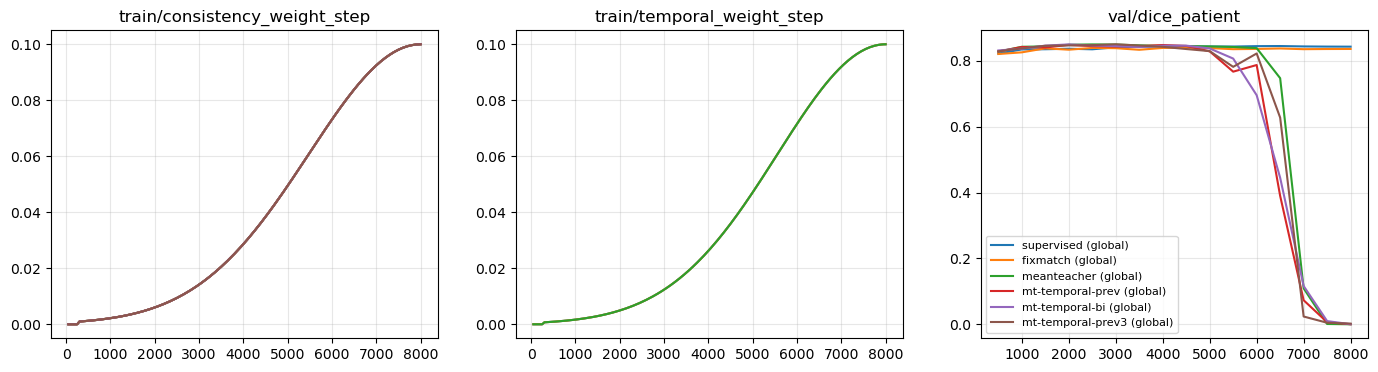

In [9]:
def metrics_of(output_dir):
    path = Path(output_dir) / "csv" / "metrics.csv"
    return pd.read_csv(path) if path.exists() else pd.DataFrame()   # fast_dev_run nao grava CSV

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for _, row in resources.iterrows():
    metrics = metrics_of(row.output_dir)
    label = f"{row.method} ({row.unlabeled_policy})"
    for ax, key in zip(axes, ["train/consistency_weight_step", "train/temporal_weight_step", "val/dice_patient"]):
        if key in metrics:
            series = metrics[["step", key]].dropna() if "step" in metrics else metrics[[key]].dropna()
            ax.plot(series.index if "step" not in series else series["step"], series[key], label=label)
            ax.set_title(key)
axes[-1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.3)

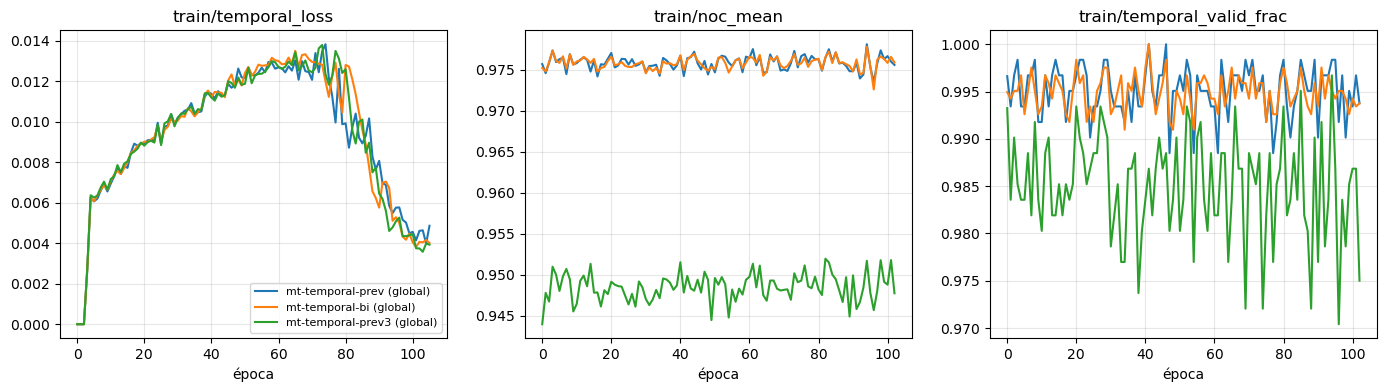

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for _, row in resources[resources.method.astype(str).str.startswith("mt-temporal")].iterrows():
    metrics = metrics_of(row.output_dir)
    for ax, key in zip(axes, ["train/temporal_loss_epoch" if "train/temporal_loss_epoch" in metrics else "train/temporal_loss",
                              "train/noc_mean", "train/temporal_valid_frac"]):
        if key in metrics:
            series = metrics[key].dropna().reset_index(drop=True)
            ax.plot(series, label=f"{row.method} ({row.unlabeled_policy})")
            ax.set_title(key)
for ax in axes:
    ax.grid(alpha=0.3); ax.set_xlabel("época")
axes[0].legend(fontsize=8)

## Por paciente (teste INCA)

In [11]:
per_patient = (results[results.eval_set == "inca_test"]
               .groupby(BY + ["paciente_id"], observed=True).dice.mean().unstack("method"))
per_patient.round(4)

method                                      fixmatch  meanteacher  \
arch          unlabeled_policy paciente_id                          
deeplabv3plus global           1              0.8847       0.8984   
                               10             0.8452       0.8493   
                               115            0.9132       0.9171   
                               12             0.8763       0.8772   
                               16             0.8489       0.8628   
                               20             0.9324       0.9331   
                               26             0.8470       0.8501   
                               27             0.8397       0.8682   
                               34             0.8917       0.9028   
                               42             0.8543       0.8857   
                               52             0.8777       0.9081   
                               56             0.9269       0.9267   
                               61             0.8654       0.8219   
                               63             0.8754       0.8706   
                               67             0.8884       0.8854   
                               69             0.8944       0.9025   
                               82             0.8803       0.9001   
                               85             0.9018       0.9074   
                               86             0.7439       0.7475   
                               88             0.8429       0.8495   
                               96             0.8565       0.8502   
                               97             0.8862       0.8830   
                               99             0.8475       0.8482   

method                                      mt-temporal-bi  mt-temporal-prev  \
arch          unlabeled_policy paciente_id                                     
deeplabv3plus global           1                    0.8975            0.9007   
                               10                   0.8469            0.8489   
                               115                  0.9366            0.9499   
                               12                   0.8770            0.8723   
                               16                   0.8562            0.8283   
                               20                   0.9288            0.9309   
                               26                   0.8510            0.8531   
                               27                   0.8449            0.8533   
                               34                   0.9127            0.8994   
                               42                   0.8812            0.8632   
                               52                   0.9133            0.9076   
                               56                   0.9212            0.9117   
                               61                   0.8453            0.8000   
                               63                   0.8575            0.8753   
                               67                   0.8853            0.8854   
                               69                   0.9045            0.9055   
                               82                   0.8955            0.8959   
                               85                   0.9016            0.9070   
                               86                   0.7316            0.7282   
                               88                   0.8510            0.8449   
                               96                   0.8733            0.8669   
                               97                   0.8901            0.8830   
                               99                   0.8602            0.8510   

method                                      mt-temporal-prev3  supervised  
arch          unlabeled_policy paciente_id                                 
deeplabv3plus global           1                       0.8967      0.8946  
                               10            

In [12]:
# preciso checar:
# - porque todos os mean teacher tiveram deterioracao no final do treino?
# - qual o impacto da loss temporal?
# - quais os resultados qualitativos? Deveria usar alguma metrica de estabilidade temporal?
# - Deveria comparar com o proprio DTC-TRUS?
